In [1]:
import torch
from torch import Tensor, nn
from torch.optim import Optimizer
from torch.utils.data import DataLoader
from datasets import load_from_disk
import matplotlib.pyplot as plt

from pathlib import Path
from collections.abc import Callable
import sys

if "/content/src" not in sys.path:
    sys.path.insert(0, "/content/src")

from restore_pipeline.dataprocessing.dataloading import (
    DataConfig,
    get_damaged_splits_dataloaders,
)
from restore_pipeline.inpainting.unet import UNet
from restore_pipeline.inpainting.train_model import train_model

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!unzip -oq "/content/drive/MyDrive/wikiart_train_processed.zip" -d /content

In [5]:
processed_path = Path("/content/wikiart_train_processed")
if not (processed_path / "dataset_info.json").is_file():
    raise FileNotFoundError(f"Saved WikiArt dataset not found at {processed_path.resolve()}")

In [6]:
cfg = DataConfig(processed_path=processed_path, batch_size=64, num_workers=2)
train_dl, val_dl, test_dl = get_damaged_splits_dataloaders(cfg)

In [7]:
batch = next(iter(train_dl))
damaged = batch["image"]   # model input
clean = batch["target"]    # reconstruction target
print(damaged.shape, clean.shape)

torch.Size([64, 3, 256, 256]) torch.Size([64, 3, 256, 256])


In [8]:
changed = (damaged - clean).abs().amax(dim=1) > 1e-6
changed_pixels = changed.flatten(1).sum(dim=1)

print("Changed pixels per image:", changed_pixels.tolist())

Changed pixels per image: [356, 3228, 1958, 2262, 1184, 3921, 1510, 2907, 979, 1994, 1285, 411, 3651, 434, 943, 2339, 2277, 441, 208, 1033, 2170, 2994, 2547, 191, 3745, 843, 1364, 440, 1925, 1356, 571, 1703, 3369, 3842, 2349, 3169, 3567, 1019, 2730, 3660, 2851, 2838, 512, 2990, 415, 2483, 1588, 2571, 434, 2891, 305, 1103, 865, 2410, 4029, 2462, 1050, 531, 2130, 857, 415, 748, 2412, 509]


In [9]:
ds = load_from_disk(str(cfg.processed_path))
print(ds.column_names)

styles = ds.unique("style")

print(f"Number of styles: {len(styles)}")
print(f"Styles: {styles}")

['title', 'artist', 'date', 'genre', 'style', 'filename', 'image']
Number of styles: 138
Styles: ['new realism', 'surrealism', 'expressionism', 'art nouveau (modern)', 'symbolism', 'realism', 'early renaissance', 'divisionism', 'romanticism', 'post-impressionism', 'impressionism', 'baroque', 'naïve art (primitivism)', 'fauvism', 'pointillism', 'pop art', 'abstract expressionism', 'neo-dada', 'art informel', 'abstract art', 'luminism', 'neoclassicism', 'cubism', 'mannerism (late renaissance)', 'op art', 'neo-rococo', 'neo-expressionism', 'proto renaissance', 'gongbi', 'neo-romanticism', 'shin-hanga', 'none', 'hard edge painting', 'minimalism', 'northern renaissance', 'high renaissance', 'academicism', 'modernismo', 'ukiyo-e', 'cloisonnism', 'precisionism', 'rococo', 'classicism', 'intimism', 'magic realism', 'american realism', 'regionalism', 'lyrical abstraction', 'purism', 'tachisme', 'synthetic cubism', 'art deco', None, 'action painting', 'native art', 'futurism', 'tonalism', 'color

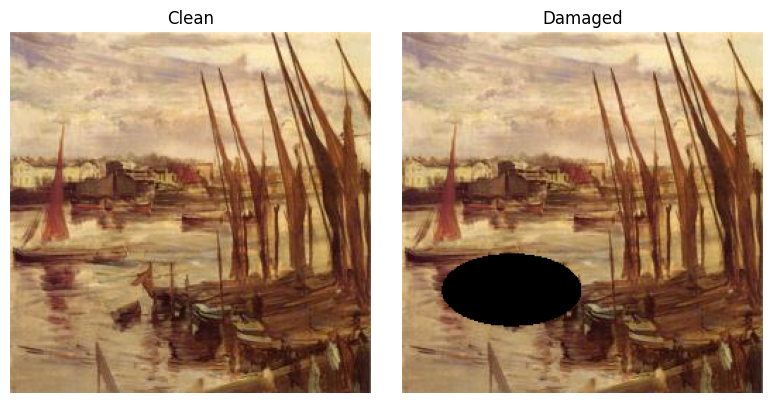

In [10]:
i = changed_pixels.argmax().item()  # Same index selects the matching clean and damaged images.

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, image, title in zip(axes, (clean[i], damaged[i]), ("Clean", "Damaged")):
    image = image.detach().cpu().permute(1, 2, 0)  # CHW → HWC
    ax.imshow(image.clamp(0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Style tuned U-Net

In [11]:
styles = sorted(
    s for s in ds.unique("style")
    if s is not None and s.lower() != "none"
)

style_to_id = {"unknown": 0}

style_to_id.update({
    style: i + 1
    for i, style in enumerate(styles)
})

num_styles = len(style_to_id)

print(f"Known styles: {len(styles)}")
print(f"Total conditions: {num_styles}")

Known styles: 136
Total conditions: 137


In [12]:
history = {}

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(
    num_classes=3,
    num_conditions=len(style_to_id),
)

global_weights = torch.load(
    "/content/drive/MyDrive/uczenie_nienadzorowane/unet_no_styles_hybrid.pt",
    map_location="cpu",
    weights_only=True,
)

result = model.load_state_dict(global_weights, strict=False)

assert set(result.missing_keys) == {
    "condition_embedding.weight",
    "condition_film.weight",
    "condition_film.bias",
}
assert not result.unexpected_keys

model = model.to(device)

opt = torch.optim.AdamW(model.parameters(), lr=1e-4)

In [14]:
history = train_model(
    model,
    opt,
    train_dl,
    val_dl,
    test_dl,
    epochs=3,
    save_path="/content/drive/MyDrive/uczenie_nienadzorowane/unet_styles.pt",
    conditioning="style",
    label_to_id=style_to_id,
    checkpoint_every=100,
)

Resumed: epoch 3, phase=val, batch=1287
Device: cuda:0
Mixed precision: True
Conditioning: style
Training batches: 1287
Validation batches: 161
Epochs: 3
Checkpoint interval: 100



Epoch 3/3 [Val masked L1]:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 03/3 | Train hybrid: 0.0709 | Val masked L1: 0.0698 | Time: 89.6s | Best saved!

Best epoch: 3 | Best masked val L1: 0.0698


Test masked L1:   0%|          | 0/161 [00:00<?, ?it/s]

Test masked L1: 0.0692


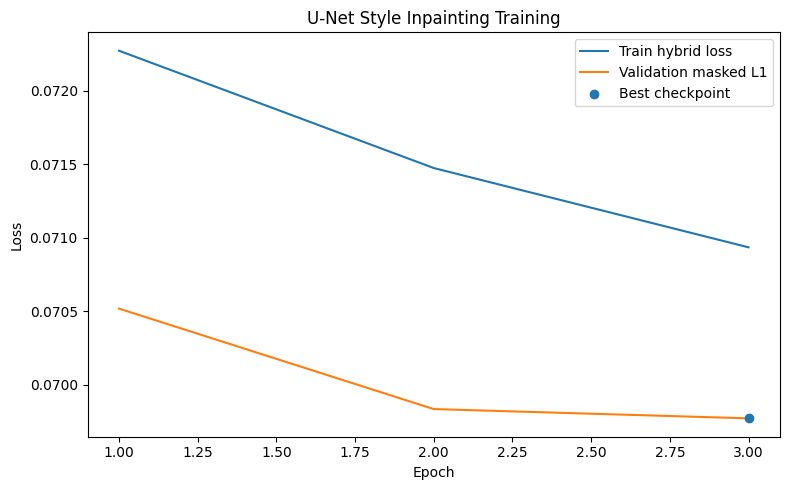

In [15]:
epochs = range(1, len(history["val"]) + 1)
best_epoch = min(epochs, key=lambda e: history["val"][e - 1])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, history["train"], label="Train hybrid loss")
ax.plot(epochs, history["val"], label="Validation masked L1")

ax.scatter(
    best_epoch,
    history["val"][best_epoch - 1],
    label="Best checkpoint",
    zorder=5,
)

ax.set(
    xlabel="Epoch",
    ylabel="Loss",
    title="U-Net Style Inpainting Training",
)

ax.legend()
fig.tight_layout()
plt.show()

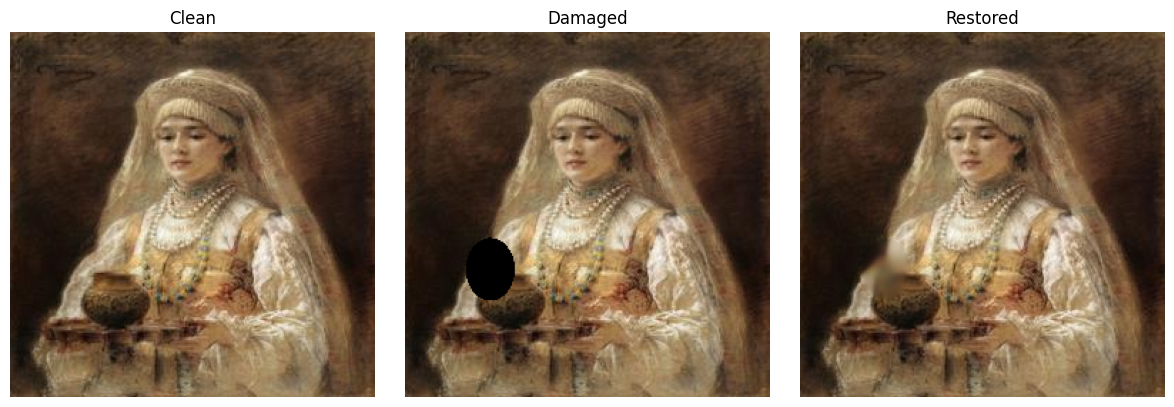

In [22]:
i = 4
device = next(model.parameters()).device
styles = batch["style"]
style = styles[i]

if style is None or style == "none":
    style = "unknown"

style_id = torch.tensor(
    [style_to_id[style]],
    dtype=torch.long,
    device=device,
)

model.eval()
with torch.inference_mode():
    restored = model(
        damaged[i:i + 1].to(device),
        style_id,
    )[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, image, title in zip(
    axes,
    (clean[i], damaged[i], restored),
    ("Clean", "Damaged", "Restored"),
):
    image = image.detach().cpu().permute(1, 2, 0)
    ax.imshow(image.clamp(0, 1))
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
plt.show()

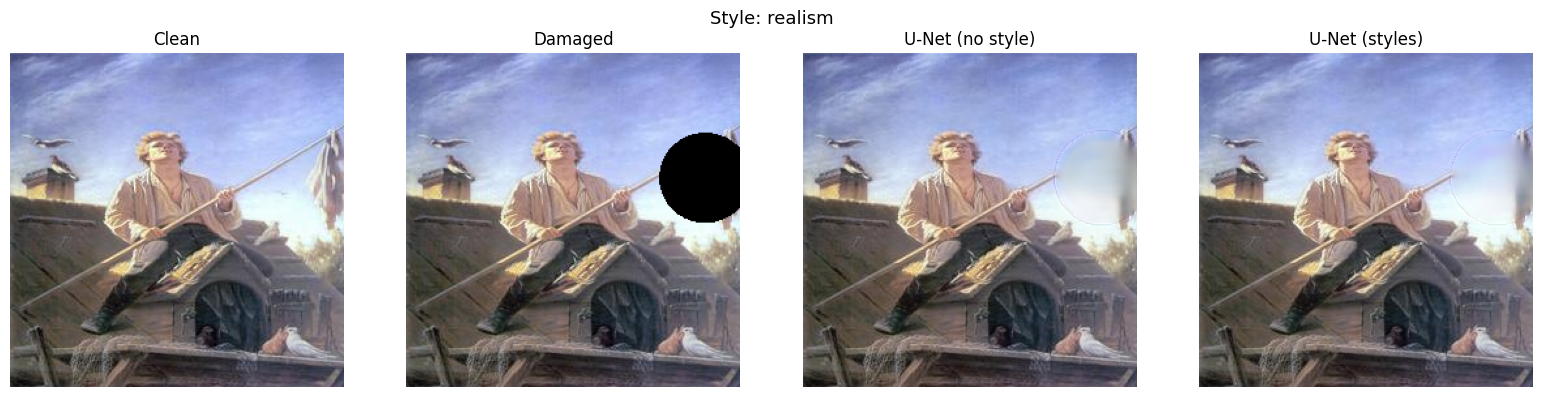

In [34]:
i = 36
device = next(model.parameters()).device

# Load U-Net without conditioning
no_style_model = UNet(num_classes=3).to(device)
no_style_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/uczenie_nienadzorowane/unet_no_styles_hybrid.pt",
        map_location=device,
        weights_only=True,
    )
)

model.eval()
no_style_model.eval()

# Style conditioning
style = batch["style"][i]
if style is None or style == "none":
    style = "unknown"

style_id = torch.tensor(
    [style_to_id[style]],
    dtype=torch.long,
    device=device,
)

# Same input for both models
x = damaged[i:i + 1].to(device)

with torch.inference_mode():
    restored_film = model(x, style_id)[0]
    restored_baseline = no_style_model(x)[0]

# Compare
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, image, title in zip(
    axes,
    (clean[i], damaged[i], restored_baseline, restored_film),
    ("Clean", "Damaged", "U-Net (no style)", "U-Net (styles)"),
):
    image = image.detach().cpu().permute(1, 2, 0)
    ax.imshow(image.clamp(0, 1))
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"Style: {style}", fontsize=13)
fig.tight_layout()
plt.show()